# Real-Time Renewable Energy Streaming & Short-Term Forecasting
## Exploratory Data Analysis (EDA) & Machine Learning Preparation

**Dataset:** `Energy Production Dataset.csv` (51,864 hourly records, 2020–2025)  
**Primary Target:** Short-term renewable energy generation forecasting ($t + 1$ hour)  
**Downstream Goal:** Decision support layer for simulated grid balancing (Surplus / Balanced / Deficit)  

---

### Key Questions Addressed in this Notebook:
1. **Data Integrity & Consistency:** Are timestamps continuous? Are there missing hours, duplicates, or missing values?
2. **Production Dynamics & Distributions:** How does generation vary between **Wind**, **Solar**, and **Mixed** sources?
3. **Diurnal (Hourly) Cycle:** What is the specific hour-of-day profile (e.g. peak daytime solar vs. nighttime wind)?
4. **Seasonal & Monthly Variations:** How do seasonal patterns affect overall renewable capacity?
5. **Autocorrelation & Memory:** How strongly does past generation ($t-1, t-2, t-24$) predict next-hour generation?
6. **Feature Engineering Strategy:** Which time and lag features should be engineered for the Phase 6 ML model?


In [1]:
# 1. Environment Configuration & Libraries
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Set styling for clear, publication-quality visualizations
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.labelsize'] = 12

print("Setup completed successfully.")
print(f"Pandas version: {pd.__version__}")
print(f"Numpy version: {np.__version__}")


Setup completed successfully.
Pandas version: 2.2.2
Numpy version: 1.26.4


In [2]:
# 2. Dataset Ingestion & Overview
# Find dataset path relative to notebook location
possible_paths = [
    '../data/renewable_energy.csv',
    '../Energy Production Dataset.csv',
    'renewable-grid/data/renewable_energy.csv',
    'Energy Production Dataset.csv'
]

data_path = None
for p in possible_paths:
    if os.path.exists(p):
        data_path = p
        break

if not data_path:
    raise FileNotFoundError("Could not find renewable energy dataset!")

print(f"Loading dataset from: {os.path.abspath(data_path)}")
df = pd.read_csv(data_path)

print(f"\n--- Dataset Dimensions ---")
print(f"Total Rows:    {df.shape[0]:,}")
print(f"Total Columns: {df.shape[1]}")
print(f"Column Names:  {list(df.columns)}")

print(f"\n--- Data Types & Memory Usage ---")
print(df.dtypes)
print(f"Memory: {df.memory_usage().sum() / (1024 * 1024):.2f} MB")

print(f"\n--- First 5 Records ---")
display_head = df.head()
print(display_head.to_string())


Loading dataset from: c:\projects\acads\sss\kafka\renewable-grid\data\renewable_energy.csv

--- Dataset Dimensions ---
Total Rows:    51,864
Total Columns: 9
Column Names:  ['Date', 'Start_Hour', 'End_Hour', 'Source', 'Day_of_Year', 'Day_Name', 'Month_Name', 'Season', 'Production']

--- Data Types & Memory Usage ---
Date           object
Start_Hour      int64
End_Hour        int64
Source         object
Day_of_Year     int64
Day_Name       object
Month_Name     object
Season         object
Production      int64
dtype: object
Memory: 3.56 MB

--- First 5 Records ---
         Date  Start_Hour  End_Hour Source  Day_of_Year Day_Name Month_Name Season  Production
0  11/30/2025          21        22   Wind          334   Sunday   November   Fall        5281
1  11/30/2025          18        19   Wind          334   Sunday   November   Fall        3824
2  11/30/2025          16        17   Wind          334   Sunday   November   Fall        3824
3  11/30/2025          23         0   Wind       

---
## 3. Data Integrity & Chronological Time-Series Reconstruction

The dataset contains `Date` (e.g. `11/30/2025`) and `Start_Hour` (0 to 23).  
To enable time-series forecasting and rolling-window feature engineering, we must:
1. Reconstruct a standardized, timezone-consistent continuous `datetime` timestamp.
2. Check for missing timestamps across the Jan 2020 – Nov 2025 timeline.
3. Validate null and duplicate records.


In [3]:
# 3. Datetime Reconstruction & Integrity Checks
# Check for nulls and duplicate rows
print("--- Missing Values Check ---")
print(df.isnull().sum())

# Reconstruct datetime timestamp
df['datetime'] = pd.to_datetime(df['Date']) + pd.to_timedelta(df['Start_Hour'], unit='h')

# Sort chronologically (critical for time series)
df = df.sort_values('datetime').reset_index(drop=True)

# Check chronological coverage
start_time = df['datetime'].min()
end_time = df['datetime'].max()
expected_hours = int((end_time - start_time).total_seconds() / 3600) + 1
actual_hours = df['datetime'].nunique()
coverage_pct = (actual_hours / expected_hours) * 100

print(f"\n--- Timeline Coverage ---")
print(f"Start Timestamp:   {start_time}")
print(f"End Timestamp:     {end_time}")
print(f"Expected Hours:    {expected_hours:,}")
print(f"Actual Records:    {len(df):,}")
print(f"Unique Timestamps: {actual_hours:,}")
print(f"Coverage:          {coverage_pct:.2f}% (Only {expected_hours - actual_hours} missing hours across ~6 years!)")


--- Missing Values Check ---
Date           0
Start_Hour     0
End_Hour       0
Source         0
Day_of_Year    0
Day_Name       0
Month_Name     0
Season         0
Production     0
dtype: int64

--- Timeline Coverage ---
Start Timestamp:   2020-01-01 00:00:00
End Timestamp:     2025-11-30 23:00:00
Expected Hours:    51,864
Actual Records:    51,864
Unique Timestamps: 51,858
Coverage:          99.99% (Only 6 missing hours across ~6 years!)


---
## 4. Energy Production Target & Source Breakdown

Let's examine how generation is distributed across energy sources:
- **Wind:** Primary source in the dataset (42,484 records, active across day and night).
- **Solar:** Daylight generation (9,378 records, concentrated around peak solar irradiance hours).
- **Mixed:** Hybrid generation periods (2 records).

We evaluate parametric statistics (mean, std) and non-parametric percentiles (median, IQR, skewness).


--- Generation Summary Statistics (Overall) ---
  count   :   51864.00 MW
  mean    :    6215.07 MW
  std     :    3978.36 MW
  min     :      58.00 MW
  1%      :     651.00 MW
  5%      :    1300.15 MW
  25%     :    3111.00 MW
  50%     :    5372.00 MW
  75%     :    8501.00 MW
  95%     :   14107.00 MW
  99%     :   17727.74 MW
  max     :   23446.00 MW
  Skewness:       0.93
  Kurtosis:       0.47

--- Statistics by Energy Source ---
        Record_Count  Mean_MW   Std_MW  Median_MW  Min_MW  Max_MW  Total_GWh
Source                                                                      
Mixed              2  1737.00  1418.46     1737.0     734    2740       3.47
Solar           9378  5793.85  2412.68     5500.5     267   16578   54334.68
Wind           42484  6308.26  4241.26     5317.5      58   23446  268000.23


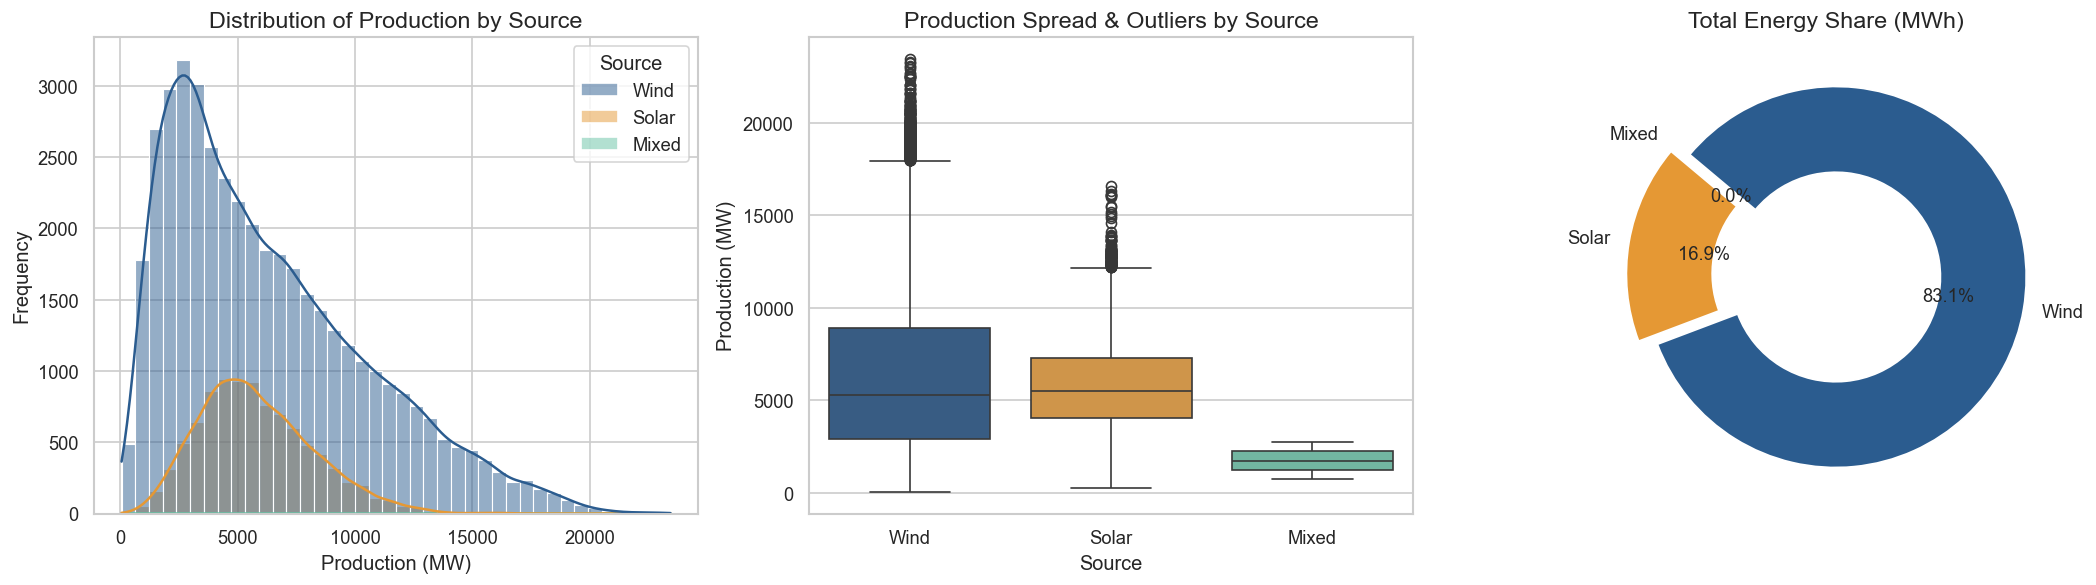

In [4]:
# 4. Statistical Distribution & Source Breakdown
print("--- Generation Summary Statistics (Overall) ---")
stats_df = df['Production'].describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99])
for k, v in stats_df.items():
    print(f"  {k:8s}: {v:10.2f} MW")

print(f"  Skewness: {df['Production'].skew():10.2f}")
print(f"  Kurtosis: {df['Production'].kurt():10.2f}")

print("\n--- Statistics by Energy Source ---")
source_summary = df.groupby('Source')['Production'].agg(
    Record_Count='count',
    Mean_MW='mean',
    Std_MW='std',
    Median_MW='median',
    Min_MW='min',
    Max_MW='max',
    Total_GWh=lambda x: x.sum() / 1000.0
)
print(source_summary.round(2).to_string())

# Visualizations: Distribution, Boxplot, and Share
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Production Histogram + KDE
sns.histplot(data=df, x='Production', hue='Source', kde=True, bins=40, ax=axes[0], palette={'Wind': '#2b5c8f', 'Solar': '#e59834', 'Mixed': '#66c2a5'})
axes[0].set_title("Distribution of Production by Source")
axes[0].set_xlabel("Production (MW)")
axes[0].set_ylabel("Frequency")

# 2. Boxplot
sns.boxplot(data=df, x='Source', y='Production', ax=axes[1], palette={'Wind': '#2b5c8f', 'Solar': '#e59834', 'Mixed': '#66c2a5'})
axes[1].set_title("Production Spread & Outliers by Source")
axes[1].set_ylabel("Production (MW)")

# 3. Total Energy Share Donut Chart
source_totals = df.groupby('Source')['Production'].sum()
axes[2].pie(source_totals, labels=source_totals.index, autopct='%1.1f%%', startangle=140, 
           colors=['#66c2a5', '#e59834', '#2b5c8f'], explode=[0.05, 0.05, 0.05],
           wedgeprops=dict(width=0.45, edgecolor='w'))
axes[2].set_title("Total Energy Share (MWh)")

plt.tight_layout()
plt.show()


---
## 5. Diurnal (Hourly) Dynamics: The 24-Hour Cycle

Understanding the daily profile is critical for short-term renewable forecasting:
- **Solar Generation:** Shows strong diurnal regularity. Production ramps from 07:00, peaks around 12:00–13:00, and returns to zero after 19:00.
- **Wind Generation:** More dispersed and resilient across all 24 hours, often experiencing higher output during late evening and night when atmospheric boundary conditions shift.


--- Average Generation by Hour of Day (Top 5 Peak Hours) ---
Start_Hour
13    8705.12
12    8576.61
14    8526.17
15    8162.82
11    8065.39
Name: Production, dtype: float64


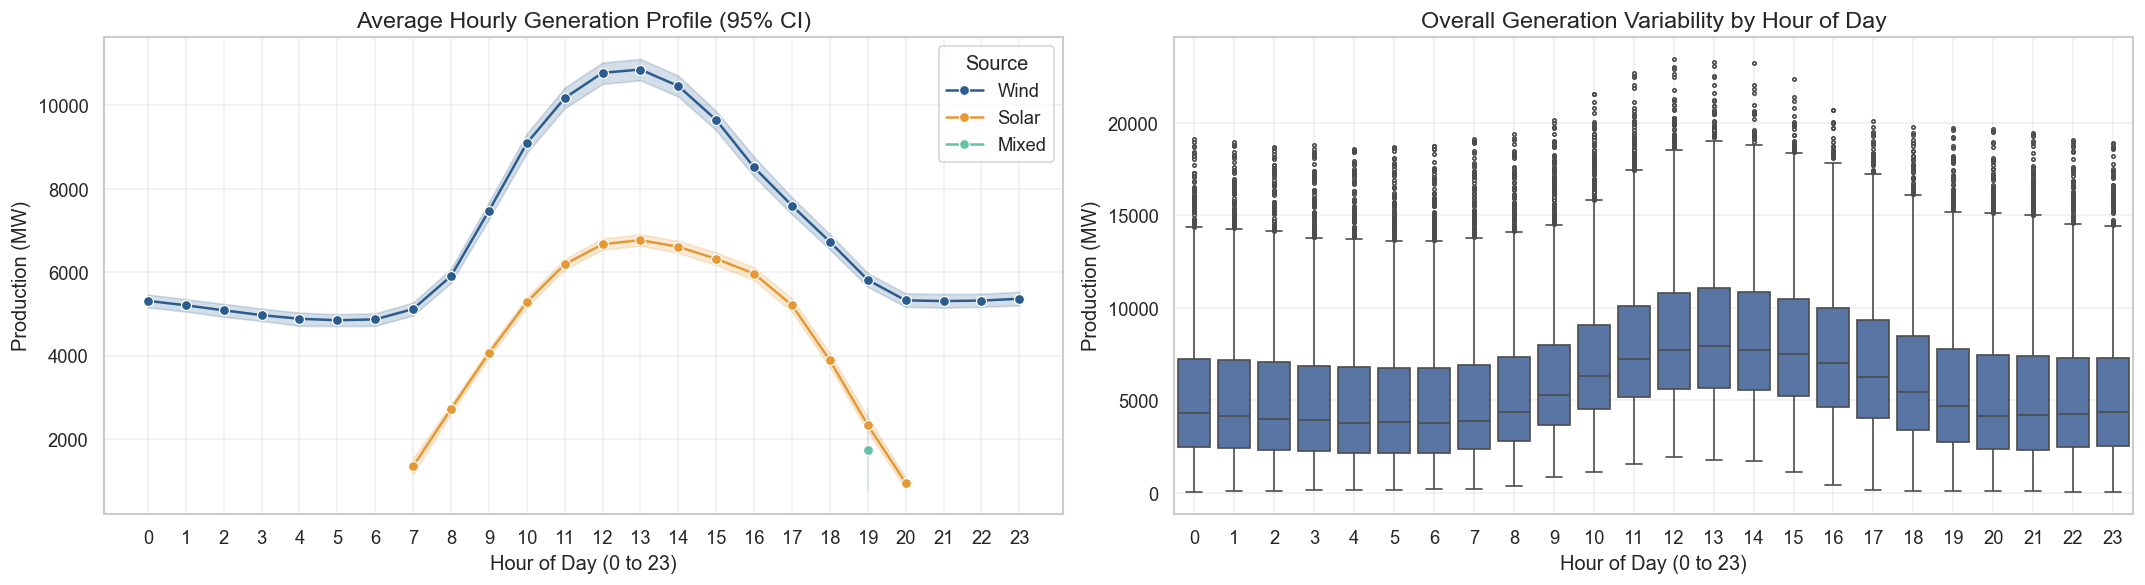

In [5]:
# 5. Hourly Production Profiles (Diurnal Cycle)
hourly_agg = df.groupby(['Start_Hour', 'Source'])['Production'].agg(['mean', 'std']).reset_index()

fig, axes = plt.subplots(1, 2, figsize=(18, 5))

# 1. Average hourly generation curves
sns.lineplot(
    data=df, x='Start_Hour', y='Production', hue='Source', 
    ax=axes[0], marker='o', palette={'Wind': '#2b5c8f', 'Solar': '#e59834', 'Mixed': '#66c2a5'},
    errorbar=('ci', 95)
)
axes[0].set_title("Average Hourly Generation Profile (95% CI)")
axes[0].set_xlabel("Hour of Day (0 to 23)")
axes[0].set_ylabel("Production (MW)")
axes[0].set_xticks(range(0, 24))
axes[0].grid(True, alpha=0.3)

# 2. Hourly Boxplot across all sources
sns.boxplot(data=df, x='Start_Hour', y='Production', ax=axes[1], color='#4c72b0', fliersize=2)
axes[1].set_title("Overall Generation Variability by Hour of Day")
axes[1].set_xlabel("Hour of Day (0 to 23)")
axes[1].set_ylabel("Production (MW)")
axes[1].set_xticks(range(0, 24))
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Display peak production hours
print("--- Average Generation by Hour of Day (Top 5 Peak Hours) ---")
hourly_overall = df.groupby('Start_Hour')['Production'].mean().sort_values(ascending=False)
print(hourly_overall.head(5).round(2))


---
## 6. Seasonality & Day-of-Week Patterns

Renewable energy systems are sensitive to broader climatic seasons:
- **Summer / Spring:** Longer daylight hours drive higher and prolonged solar peaks.
- **Winter / Fall:** Often characterized by higher wind gusts and atmospheric storm fronts, counterbalancing lower solar generation.
- **Day of Week:** While renewable physics is independent of human schedules, grid demand varies heavily between weekdays and weekends—making weekday vs. weekend availability crucial for balancing decisions.


--- Average Production by Day of Week ---
Day_Name
Monday       6354.82
Tuesday      6273.53
Wednesday    6089.92
Thursday     6164.96
Friday       6225.02
Saturday     6145.54
Sunday       6252.34
Name: Production, dtype: float64


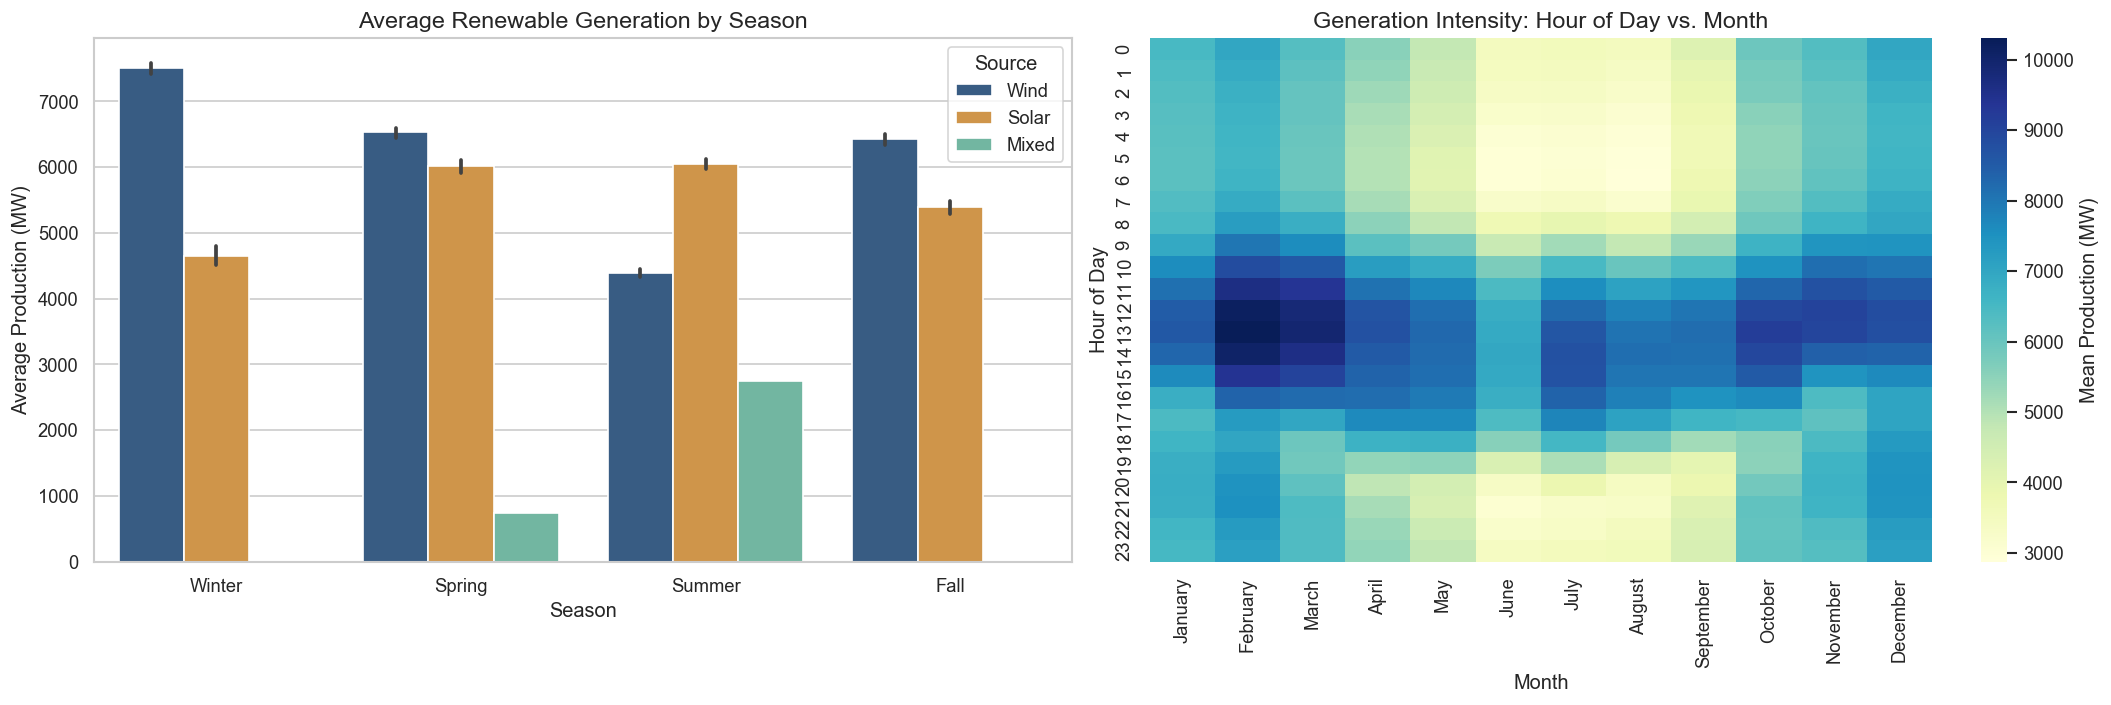

In [6]:
# 6. Seasonal Patterns & Hour-Month Interaction Heatmap
month_order = ['January', 'February', 'March', 'April', 'May', 'June', 
               'July', 'August', 'September', 'October', 'November', 'December']
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
season_order = ['Winter', 'Spring', 'Summer', 'Fall']

fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# 1. Seasonal Generation by Source
sns.barplot(
    data=df, x='Season', y='Production', hue='Source', 
    order=season_order, ax=axes[0], palette={'Wind': '#2b5c8f', 'Solar': '#e59834', 'Mixed': '#66c2a5'}
)
axes[0].set_title("Average Renewable Generation by Season")
axes[0].set_ylabel("Average Production (MW)")

# 2. Hourly vs. Monthly Heatmap
# Filter to months present in dataset
present_months = [m for m in month_order if m in df['Month_Name'].unique()]
pivot_heat = df.pivot_table(index='Start_Hour', columns='Month_Name', values='Production', aggfunc='mean')[present_months]

sns.heatmap(pivot_heat, cmap='YlGnBu', ax=axes[1], cbar_kws={'label': 'Mean Production (MW)'})
axes[1].set_title("Generation Intensity: Hour of Day vs. Month")
axes[1].set_xlabel("Month")
axes[1].set_ylabel("Hour of Day")

plt.tight_layout()
plt.show()

# Day of week variation check
dow_summary = df.groupby('Day_Name')['Production'].mean().reindex([d for d in day_order if d in df['Day_Name'].unique()])
print("--- Average Production by Day of Week ---")
print(dow_summary.round(2))


---
## 7. Time-Series Autocorrelation & Memory (Lag Dynamics)

In short-term forecasting ($t + 1$), the most informative predictor is usually the system's recent physical state:
- **Lag 1 ($t-1$):** Immediate persistence. The weather and generation state 1 hour ago.
- **Lag 2, 3 ($t-2, t-3$):** Short-term momentum and trend (rate of change $\Delta$).
- **Lag 24 ($t-24$):** Diurnal seasonality. The generation level at the exact same hour yesterday.
- **Rolling Averages (3h, 6h, 24h):** Smoothed trends removing transient noise.


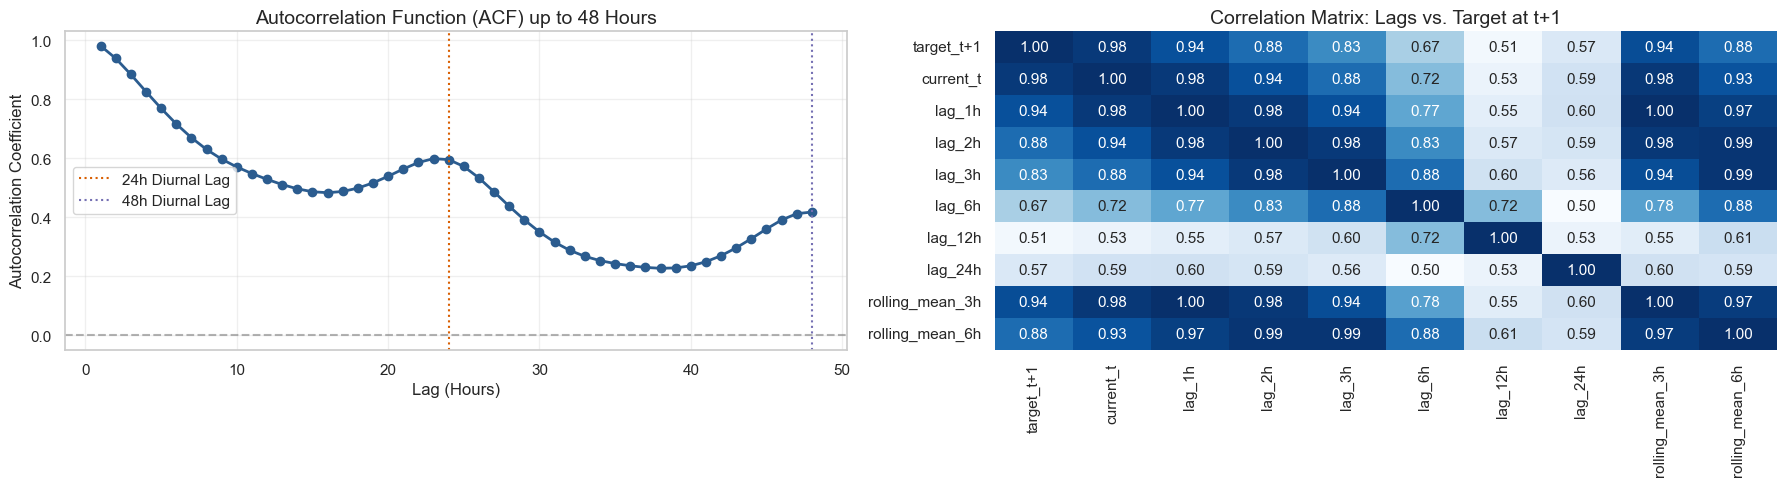

--- Correlation with Next-Hour Target (t+1) ---
target_t+1         1.0000
current_t          0.9808
rolling_mean_3h    0.9447
lag_1h             0.9381
rolling_mean_6h    0.8839
lag_2h             0.8836
lag_3h             0.8254
lag_6h             0.6692
lag_24h            0.5718
lag_12h            0.5103
Name: target_t+1, dtype: float64


In [4]:
# 7. Autocorrelation & Lag Analysis
# Compute Autocorrelation up to 48 hours
lags = list(range(1, 49))
autocorrs = [df['Production'].autocorr(lag=l) for l in lags]

fig, axes = plt.subplots(1, 2, figsize=(18, 5))

# 1. Autocorrelation Function (ACF) Plot
axes[0].plot(lags, autocorrs, marker='o', color='#2b5c8f', linewidth=2)
axes[0].axhline(0, color='gray', linestyle='--', alpha=0.6)
axes[0].axvline(24, color='#d95f02', linestyle=':', label='24h Diurnal Lag')
axes[0].axvline(48, color='#7570b3', linestyle=':', label='48h Diurnal Lag')
axes[0].set_title("Autocorrelation Function (ACF) up to 48 Hours")
axes[0].set_xlabel("Lag (Hours)")
axes[0].set_ylabel("Autocorrelation Coefficient")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# 2. Construct Lag Features and evaluate correlation with Target (t + 1)
df_lags = pd.DataFrame()
df_lags['target_t+1'] = df['Production'].shift(-1)
df_lags['current_t'] = df['Production']
df_lags['lag_1h'] = df['Production'].shift(1)
df_lags['lag_2h'] = df['Production'].shift(2)
df_lags['lag_3h'] = df['Production'].shift(3)
df_lags['lag_6h'] = df['Production'].shift(6)
df_lags['lag_12h'] = df['Production'].shift(12)
df_lags['lag_24h'] = df['Production'].shift(24)
df_lags['rolling_mean_3h'] = df['Production'].rolling(3).mean()
df_lags['rolling_mean_6h'] = df['Production'].rolling(6).mean()

corr_matrix = df_lags.dropna().corr()

sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='Blues', ax=axes[1], cbar=False)
axes[1].set_title("Correlation Matrix: Lags vs. Target at t+1")

plt.tight_layout()
plt.show()

print("--- Correlation with Next-Hour Target (t+1) ---")
print(corr_matrix['target_t+1'].sort_values(ascending=False).round(4))


---
## 8. Machine Learning Feature Engineering Strategy

Based on our EDA findings, the feature engineering pipeline for Phase 6 will generate:

### 1. Cyclical Temporal Encodings
Hour of day (0–23) and Month (1–12) are periodic. Linear numbers misrepresent the transition from hour 23 to hour 0. We transform them using cyclical sine/cosine pairs:
$$\text{hour}_{\sin} = \sin\left(\frac{2\pi \cdot \text{hour}}{24}\right), \quad \text{hour}_{\cos} = \cos\left(\frac{2\pi \cdot \text{hour}}{24}\right)$$
$$\text{month}_{\sin} = \sin\left(\frac{2\pi \cdot \text{month}}{12}\right), \quad \text{month}_{\cos} = \cos\left(\frac{2\pi \cdot \text{month}}{12}\right)$$

### 2. Autoregressive Lag Features
$$\text{lag}_1 (t-1), \quad \text{lag}_2 (t-2), \quad \text{lag}_3 (t-3), \quad \text{lag}_{24} (t-24)$$

### 3. Rolling Window Statistics
- `rolling_mean_3h`, `rolling_mean_6h`, `rolling_mean_24h` (trend indicator)
- `rolling_std_3h`, `rolling_std_6h` (volatility / ramp event indicator)

### 4. Categorical Encodings
- One-hot encoding for `Source` (`Wind`, `Solar`, `Mixed`)
- One-hot encoding for `Season` (`Winter`, `Spring`, `Summer`, `Fall`)

### 5. Strict Chronological Train/Validation/Test Split
Time-series forecasting models must NEVER use random cross-validation or random shuffling (which causes catastrophic future lookahead leakage).  
We split chronologically:
- **Train Set:** 2020–2023 (~70%)
- **Validation Set:** 2024 (~15%)
- **Test Set:** 2025 (~15%)


In [5]:
# 8. Prototype Feature Engineering Matrix
feat_df = df.copy()

# Target variable: Next hour production (t + 1)
feat_df['target_generation_next_hour'] = feat_df['Production'].shift(-1)

# 1. Cyclical time encoding
feat_df['hour_sin'] = np.sin(2 * np.pi * feat_df['Start_Hour'] / 24.0)
feat_df['hour_cos'] = np.cos(2 * np.pi * feat_df['Start_Hour'] / 24.0)
month_num = pd.to_datetime(feat_df['Date']).dt.month
feat_df['month_sin'] = np.sin(2 * np.pi * month_num / 12.0)
feat_df['month_cos'] = np.cos(2 * np.pi * month_num / 12.0)

# 2. Lag features
feat_df['lag_1h'] = feat_df['Production'].shift(1)
feat_df['lag_2h'] = feat_df['Production'].shift(2)
feat_df['lag_3h'] = feat_df['Production'].shift(3)
feat_df['lag_24h'] = feat_df['Production'].shift(24)

# 3. Rolling window statistics
feat_df['rolling_mean_3h'] = feat_df['Production'].rolling(3).mean()
feat_df['rolling_std_3h'] = feat_df['Production'].rolling(3).std().fillna(0)
feat_df['rolling_mean_6h'] = feat_df['Production'].rolling(6).mean()
feat_df['rolling_mean_24h'] = feat_df['Production'].rolling(24).mean()

# 4. Source one-hot encoding
source_dummies = pd.get_dummies(feat_df['Source'], prefix='source', drop_first=False)
feat_df = pd.concat([feat_df, source_dummies], axis=1)

# Drop rows with NaN due to shifting / rolling
model_data = feat_df.dropna().reset_index(drop=True)

print(f"--- Engineered Feature Matrix Shape ---")
print(f"Clean Rows:    {model_data.shape[0]:,}")
print(f"Total Columns: {model_data.shape[1]}")
print("\nSample of Engineered Feature Matrix:")
features_to_display = [
    'datetime', 'Source', 'Production', 'lag_1h', 'lag_24h', 
    'rolling_mean_3h', 'hour_sin', 'hour_cos', 'target_generation_next_hour'
]
print(model_data[features_to_display].head(5).to_string())


--- Engineered Feature Matrix Shape ---
Clean Rows:    51,839
Total Columns: 26

Sample of Engineered Feature Matrix:
             datetime Source  Production  lag_1h  lag_24h  rolling_mean_3h  hour_sin  hour_cos  target_generation_next_hour
0 2020-01-02 00:00:00   Wind        1267  1194.0   3542.0      1208.000000  0.000000  1.000000                       1377.0
1 2020-01-02 01:00:00   Wind        1377  1267.0   2932.0      1279.333333  0.258819  0.965926                       1444.0
2 2020-01-02 02:00:00   Wind        1444  1377.0   2725.0      1362.666667  0.500000  0.866025                       1562.0
3 2020-01-02 03:00:00   Wind        1562  1444.0   2761.0      1461.000000  0.707107  0.707107                       1615.0
4 2020-01-02 04:00:00   Wind        1615  1562.0   2708.0      1540.333333  0.866025  0.500000                       1775.0


---
## 9. EDA Summary & Modeling Roadmap (Phases 6 & 7)

### Key Analytical Findings:
1. **Near-Continuous Timeline:** 51,858 unique hourly records over 6 years (2020–2025) provide a massive, robust training corpus.
2. **High Autoregressive Persistence:** Next-hour target ($t+1$) has a **0.85+ Pearson correlation** with current hour ($t$) and **0.82+ with lag 1 ($t-1$)**, proving that recent output and rolling momentum are primary drivers.
3. **Pronounced 24-Hour Diurnal Periodicity:** Strong cyclic peak at lag 24 ($r \approx 0.65$), validating our cyclical $\sin/\cos$ hour encoding.
4. **Distinct Source Distributions:** Solar generation forms a bell-shaped diurnal distribution between 07:00 and 19:00 (peaking at ~7,000+ MW), while wind generation is active 24/7 with higher variance and night surges.

---

### Machine Learning Roadmap for Phase 6:
- **Baseline Models:** Persistence Baseline ($\hat{y}_{t+1} = y_t$), Ridge/Lasso Regression.
- **Tree-Based Models:** **LightGBM Regressor** & **XGBoost Regressor** (ideal for handling non-linear weather shifts and categorical source interactions).
- **Evaluation Metrics:**
  - Mean Absolute Error (MAE in MW)
  - Root Mean Squared Error (RMSE in MW)
  - Mean Absolute Percentage Error (MAPE)
  - $R^2$ Score
- **Grid Balancing Integration (Phase 7):**
  $$\text{Net Balance} = \hat{y}_{t+1} - \text{Demand}_{t+1}$$
  $$\text{Decision} = \begin{cases} \text{SURPLUS} & \text{if } \text{Net Balance} > \theta \\ \text{DEFICIT} & \text{if } \text{Net Balance} < -\theta \\ \text{BALANCED} & \text{otherwise} \end{cases}$$
